<a href="https://colab.research.google.com/github/tlh222k/aio/blob/main/M4/foundational-deep-learning/01-linear-regression/code/05-advertising-stochastic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [86]:
!curl -l -o advertising.csv https://raw.githubusercontent.com/tlh222k/aio/refs/heads/main/data/advertising.csv

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  3861  100  3861    0     0  19363      0 --:--:-- --:--:-- --:--:-- 19402


In [106]:
import numpy as np
import matplotlib.pyplot as plt
import random

In [89]:
data = np.genfromtxt("/content/advertising.csv", delimiter=",", skip_header=1)
data[:5]

array([[230.1,  37.8,  69.2,  22.1],
       [ 44.5,  39.3,  45.1,  10.4],
       [ 17.2,  45.9,  69.3,  12. ],
       [151.5,  41.3,  58.5,  16.5],
       [180.8,  10.8,  58.4,  17.9]])

In [96]:
tv_data = data[:,0]
radio_data = data[:,1]
newspaper_data = data[:,2]
sales_data = data[:,3]

print(f"tv_data: {tv_data[:5]}")
print(f"radio_data: {radio_data[:5]}")
print(f"newspaper_data: {newspaper_data[:5]}")
print(f"sales_data: {sales_data[:5]}")

tv_data: [230.1  44.5  17.2 151.5 180.8]
radio_data: [37.8 39.3 45.9 41.3 10.8]
newspaper_data: [69.2 45.1 69.3 58.5 58.4]
sales_data: [22.1 10.4 12.  16.5 17.9]


In [98]:
def initialize_params():
    w1 = random.gauss(mu=0.0, sigma=0.01)
    w2 = random.gauss(mu=0.0, sigma=0.01)
    w3 = random.gauss(mu=0.0, sigma=0.01)
    b  = 0

    return w1, w2, w3, b
# compute output and loss
def predict(x1, x2, x3, w1, w2, w3, b):
    return w1*x1 + w2*x2 + w3*x3 + b

def compute_loss(y_hat, y):
    return (y_hat - y)**2

# compute gradient
def compute_gradient_wi(xi, y, y_hat):
    dl_dwi = 2*xi*(y_hat-y)
    return dl_dwi

def compute_gradient_b(y, y_hat):
    dl_db = 2*(y_hat-y)
    return dl_db

# update weights
def update_weight_wi(wi, dl_dwi, lr):
    wi = wi - lr*dl_dwi
    return wi

def update_weight_b(b, dl_db, lr):
    b  = b - lr*dl_db
    return b

In [101]:
epoch_max = 50
lr = 1e-5
losses = []

w1, w2, w3, b = initialize_params()
print(w1, w2, w3, b)


for epoch in range(epoch_max):
    for i in range(N):
        # get a sample
        x1 = tv_data[i]
        x2 = radio_data[i]
        x3 = newspaper_data[i]
        y  = sales_data[i]

        # compute output
        y_hat = predict(x1, x2, x3, w1, w2, w3, b)

        # compute loss
        loss = compute_loss(y, y_hat)

        # compute gradient w1, w2, w3, b
        dl_dw1 = compute_gradient_wi(x1, y, y_hat)
        dl_dw2 = compute_gradient_wi(x2, y, y_hat)
        dl_dw3 = compute_gradient_wi(x3, y, y_hat)
        dl_db  = compute_gradient_b(y, y_hat)


        # update parameters
        w1 = update_weight_wi(w1, dl_dw1, lr)
        w2 = update_weight_wi(w2, dl_dw2, lr)
        w3 = update_weight_wi(w3, dl_dw3, lr)
        b  = update_weight_b(b, dl_db, lr)

        # logging
        losses.append(loss)

-0.01936952549762238 -0.012565128699914037 -0.009060209114441168 0


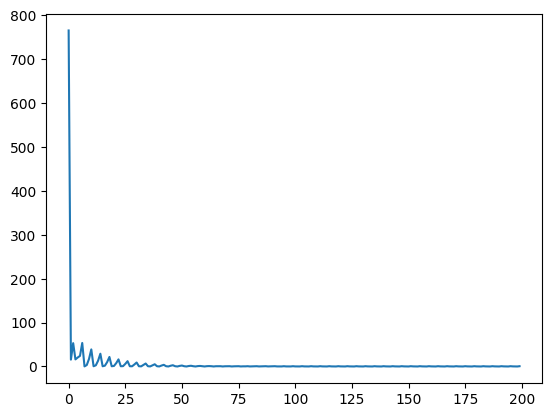

In [102]:
plt.plot(losses)
plt.show()

In [105]:
# [230.1, 37.8, 69.2, 22.1]

tv = 230.1
radio = 37.8
newspaper = 69.2

sales = predict(tv, radio, newspaper, w1, w2, w3, b)
print(f'predicted sales is {sales}')

predicted sales is 21.637761867975794
